# 4. Calibrating the trade heuristics on real trades

`DEPTH_DECAY` discounts each additional asset on a side. Instead of guessing, we pick the value that makes **real accepted trades** look most balanced, with bootstrap intervals.

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from datascience.features import *
from datascience.model import *
from datascience.collect import load_snapshots, load_trades
import json
import datascience.backtest as bt
snaps = load_snapshots(); trades = load_trades()
rows = bt.trade_table(trades, bt.value_lookup(snaps))
print(len(trades), 'trades collected;', len(rows), 'fully priced')

296 trades collected; 280 fully priced


In [2]:
grid = [0.5, 0.6, 0.645, 0.7, 0.8, 0.92, 1.0]
pd.DataFrame({'decay': grid, 'mean_sq_log_imbalance': [bt._loss(rows, d).mean() for d in grid], 'median_fairness': [np.median(bt.fairness_scores(rows, d)) for d in grid]}).round(4)

,decay,mean_sq_log_imbalance,median_fairness
0,0.500,0.1441,80.5300
1,0.600,0.1398,82.1190
2,0.645,0.1393,81.8745
3,0.700,0.1400,82.4618
4,0.800,0.1448,82.9325
5,0.920,0.1568,82.3188
6,1.000,0.1686,81.8504


In [3]:
fit = bt.fit_depth_decay(rows, boot=300)
{k: v for k, v in fit.items() if k != 'curve'}

{'best': 0.645,
 'ci90': [0.58, 0.705],
 'loss_best': 0.13933,
 'loss_old_092': 0.15678,
 'loss_no_discount': 0.16857}

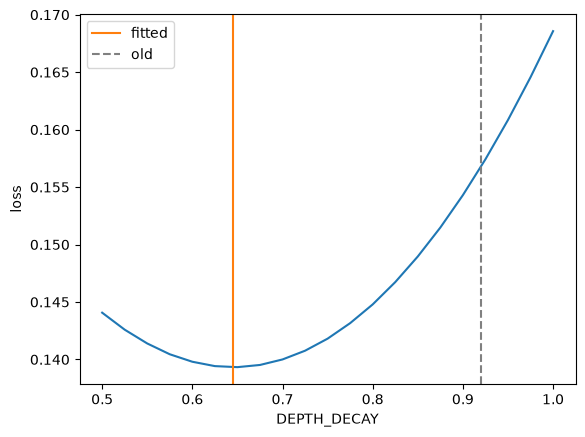

In [4]:
ds = np.array(sorted(float(k) for k in fit['curve']))
plt.plot(ds, [fit['curve'][str(d)] for d in ds]); plt.axvline(fit['best'], color='C1', label='fitted'); plt.axvline(0.92, color='grey', ls='--', label='old'); plt.legend(); plt.xlabel('DEPTH_DECAY'); plt.ylabel('loss'); plt.show()

## Fairness of real trades
The median real trade is far from perfectly even, so the 'even' threshold is set at that median (clamped to 80-95) instead of an arbitrary 90.

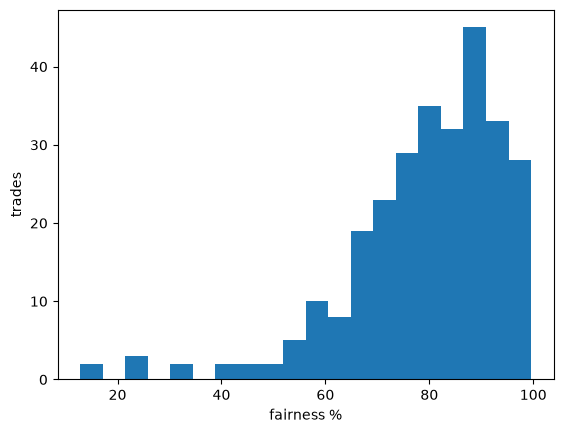

count    280.0
mean      79.2
std       15.2
min       12.8
25%       72.0
50%       81.9
75%       89.6
max       99.6
dtype: float64

In [5]:
scores = bt.fairness_scores(rows, fit['best'])
plt.hist(scores, bins=20); plt.xlabel('fairness %'); plt.ylabel('trades'); plt.show()
pd.Series(scores).describe().round(1)

## Position adjustments
A position is only adjusted if its bootstrap interval excludes zero.

In [6]:
pos = bt.fit_position_adjustments(rows, fit['best'])
pd.DataFrame(pos['report']).T, pos['applied']

(      coef               ci90 significant
 QB  0.1686   [0.0484, 0.2946]        True
 RB  0.0968   [0.0109, 0.1683]        True
 WR  0.0585  [-0.0191, 0.1426]       False
 TE  0.1461   [0.0543, 0.2346]        True,
 {'QB': 0.919, 'RB': 0.953, 'TE': 0.93})

## Forward test
Once snapshots span a week or more (run `python -m datascience.collect snapshots` daily), this checks whether the side the heuristic favors really gained more market value afterwards.

In [7]:
bt.forward_test(trades, snaps, fit['best'])

{'status': 'insufficient history (0 days between snapshots; need 7)',
 'snapshot_days': 0}